In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
#import libraries

In [ ]:
df_customer = pd.read_csv("../data/raw/customer_master.csv")  #import customer data

In [3]:
df_customer.head()

,Customer_ID,Region,Province,Segment,Account_Manager
0,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc
1,CUST00002,Western Canada,Manitoba,Mid-Market,Sophie Martin
2,CUST00003,Northern Canada,Nunavut,Small Business,Jennifer Singh
3,CUST00004,Northern Canada,Yukon,Startup,Daniel Leblanc
4,CUST00005,Atlantic Canada,Nova Scotia,Enterprise,Aisha Mohammed


In [ ]:
df_trans = pd.read_csv("../data/raw/customer_transactions.csv", 
                       parse_dates=["Transaction_Date"])  #import transaction data

In [5]:
df_trans.head()

,Transaction_ID,Customer_ID,Transaction_Date,Product_Category,Quantity,Unit_Price,Total_Amount
0,TXN000575,CUST00065,2025-02-15,Support,29,3763.82,109150.78
1,TXN000439,CUST00001,2025-02-15,Consulting,29,3312.27,96055.83
2,TXN000259,CUST00097,2025-02-15,Support,10,1127.45,11274.50
3,TXN000088,CUST00017,2025-02-15,Support,34,2714.74,92301.16
4,TXN000166,CUST00084,2025-02-15,Consulting,24,848.75,20370.00


In [6]:
df_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Customer_ID      200 non-null    object
 1   Region           200 non-null    object
 2   Province         200 non-null    object
 3   Segment          200 non-null    object
 4   Account_Manager  200 non-null    object
dtypes: object(5)
memory usage: 7.9+ KB


In [7]:
df_trans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    1000 non-null   object        
 1   Customer_ID       1000 non-null   object        
 2   Transaction_Date  1000 non-null   datetime64[ns]
 3   Product_Category  1000 non-null   object        
 4   Quantity          1000 non-null   int64         
 5   Unit_Price        1000 non-null   float64       
 6   Total_Amount      1000 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 54.8+ KB


**Imported both the Customer dataset and Transaction dataset. Now to combine them on the Customer ID**

In [8]:
df=pd.merge(df_customer, df_trans,
         how = 'inner', on='Customer_ID')

In [9]:
df.head()

,Customer_ID,Region,Province,Segment,Account_Manager,Transaction_ID,Transaction_Date,Product_Category,Quantity,Unit_Price,Total_Amount
0,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000439,2025-02-15,Consulting,29,3312.27,96055.83
1,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000172,2025-03-20,Support,19,1803.64,34269.16
2,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000471,2025-06-19,Software,43,4866.73,209269.39
3,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000532,2025-07-12,Services,28,3824.11,107075.08
4,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000444,2026-01-29,Software,38,3700.26,140609.88


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Customer_ID       1000 non-null   object        
 1   Region            1000 non-null   object        
 2   Province          1000 non-null   object        
 3   Segment           1000 non-null   object        
 4   Account_Manager   1000 non-null   object        
 5   Transaction_ID    1000 non-null   object        
 6   Transaction_Date  1000 non-null   datetime64[ns]
 7   Product_Category  1000 non-null   object        
 8   Quantity          1000 non-null   int64         
 9   Unit_Price        1000 non-null   float64       
 10  Total_Amount      1000 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(7)
memory usage: 86.1+ KB


In [11]:
#pip install dtale  #install dtale for EDA

In [12]:
import dtale
#dtale.show(df)

<Axes: ylabel='Quantity'>

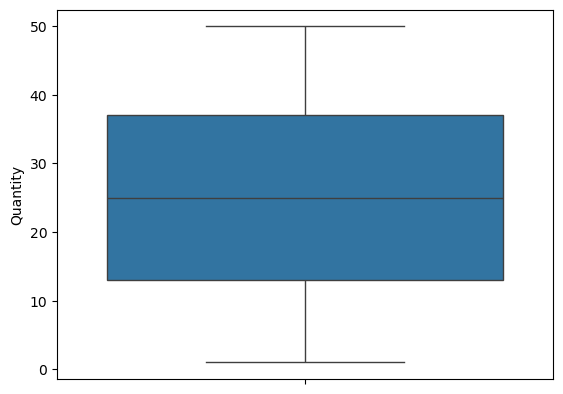

In [13]:
sns.boxplot(y='Quantity', data=df)

<Axes: ylabel='Unit_Price'>

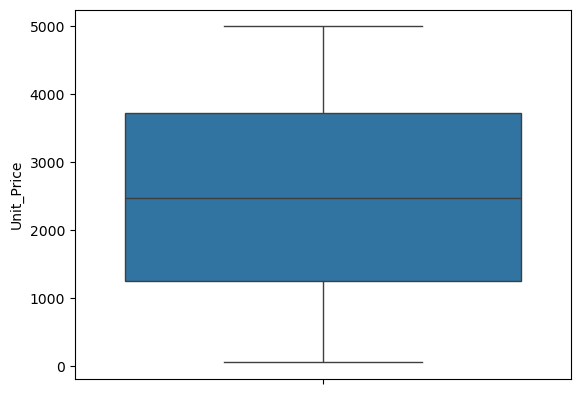

In [14]:
sns.boxplot(y='Unit_Price', data=df)

<Axes: ylabel='Total_Amount'>

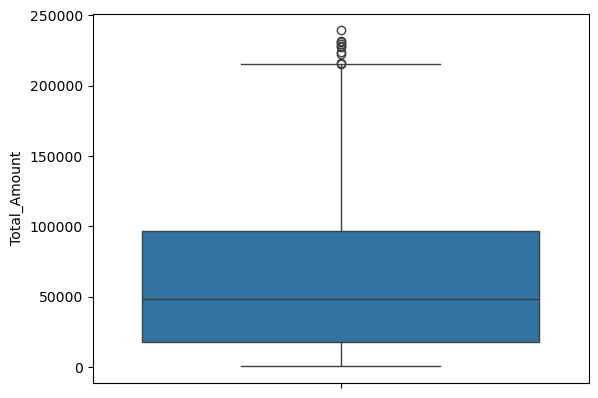

In [15]:
sns.boxplot(y='Total_Amount', data=df)

In [16]:
df[['Quantity', 'Unit_Price', 'Total_Amount']].describe()

,Quantity,Unit_Price,Total_Amount
count,1000.000000,1000.000000,1000.000000
mean,25.454000,2490.787530,64140.046350
std,14.311768,1422.518923,55234.368523
min,1.000000,53.230000,489.480000
25%,13.000000,1245.425000,17938.702500
50%,25.000000,2466.415000,48337.375000
75%,37.000000,3721.885000,96866.880000
max,50.000000,4997.810000,239422.820000


In [17]:
df.describe(include='object')

,Customer_ID,Region,Province,Segment,Account_Manager,Transaction_ID,Product_Category
count,1000,1000,1000,1000,1000,1000,1000
unique,199,4,13,4,16,1000,6
top,CUST00060,Atlantic Canada,Northwest Territories,Small Business,David Kim,TXN000439,Consulting
freq,11,329,130,384,88,1,186


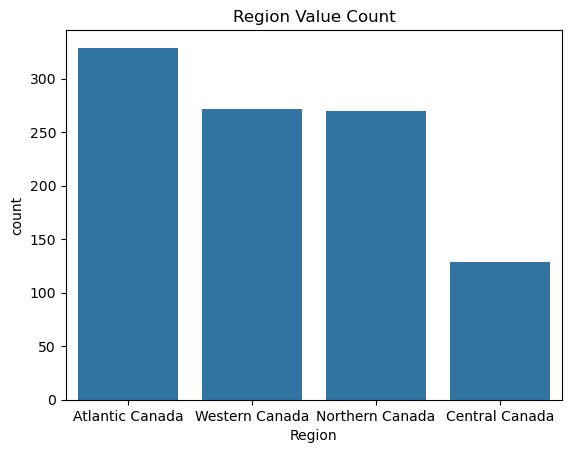

In [18]:
sns.countplot(x='Region', data=df)
plt.title('Region Value Count')
plt.show()

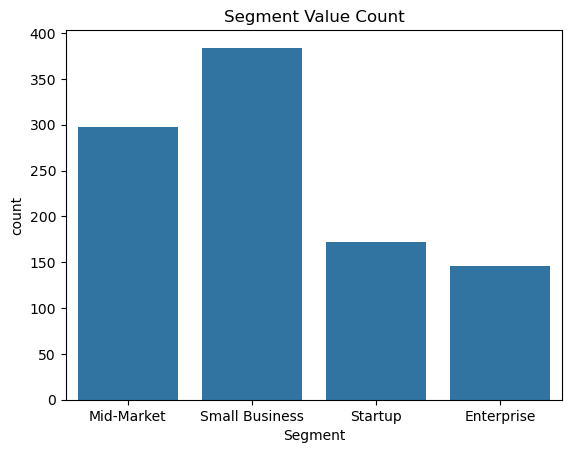

In [19]:
sns.countplot(x='Segment', data=df)
plt.title('Segment Value Count')
plt.show()

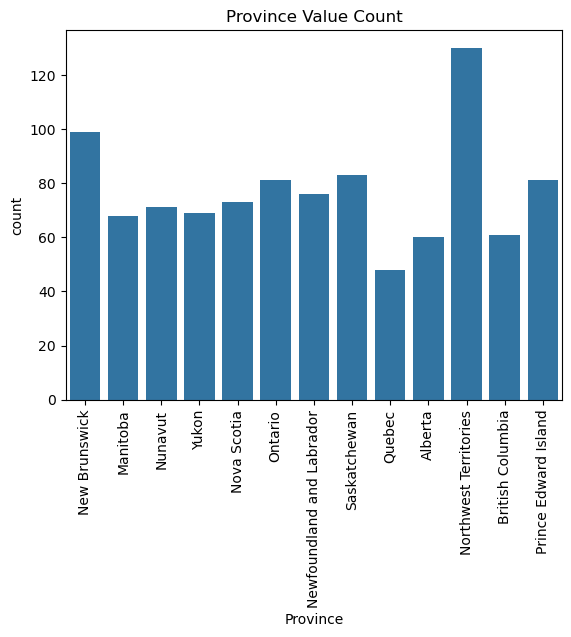

In [20]:
sns.countplot(x='Province', data=df)
plt.title('Province Value Count')
plt.xticks(rotation=90)
plt.show()

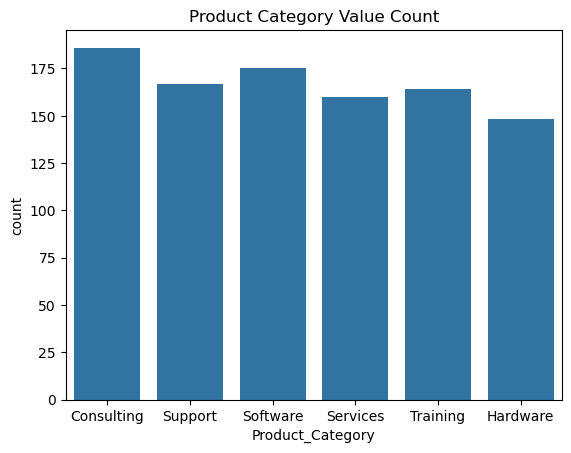

In [21]:
sns.countplot(x='Product_Category', data=df)
plt.title('Product Category Value Count')
plt.show()

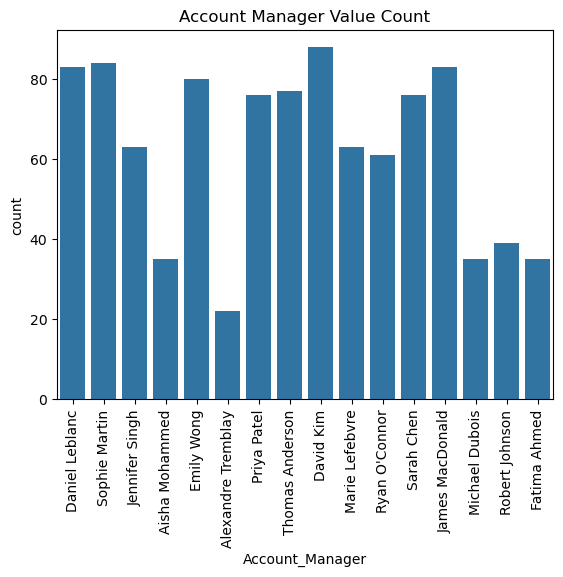

In [22]:
sns.countplot(x='Account_Manager', data=df)
plt.title('Account Manager Value Count')
plt.xticks(rotation=90)
plt.show()

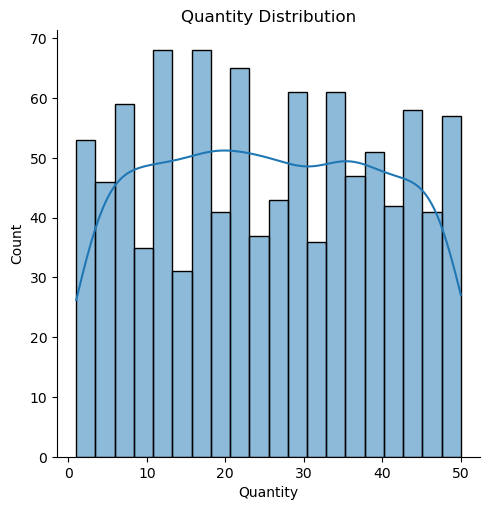

In [23]:
sns.displot(df['Quantity'], bins=20, kde='True')
plt.title('Quantity Distribution')
plt.show()

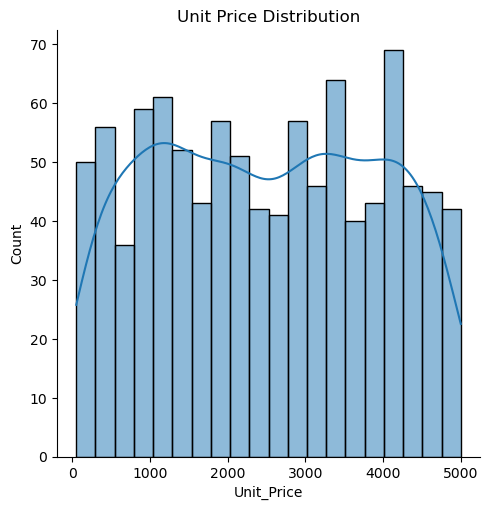

In [24]:
sns.displot(df['Unit_Price'], bins=20, kde='True')
plt.title('Unit Price Distribution')
plt.show()

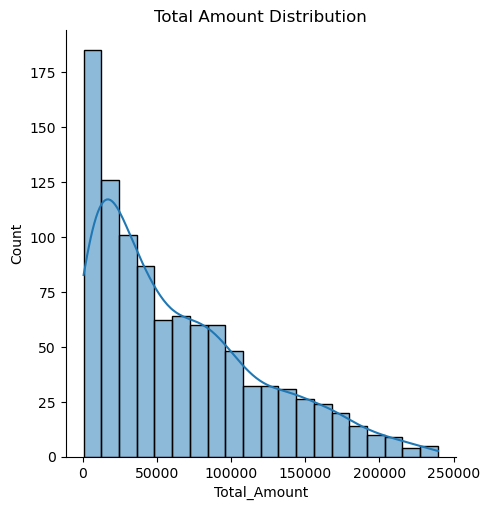

In [25]:
sns.displot(df['Total_Amount'], bins=20, kde='True')
plt.title('Total Amount Distribution')
plt.show()

**Splitting the dataset for forecasting, one data set for volumes and another for total sales.**

In [26]:
df_Quantity = df.groupby('Transaction_Date', )['Quantity'].sum().reset_index()

In [27]:
df_Quantity.head(10)

,Transaction_Date,Quantity
0,2025-02-15,193
1,2025-02-16,23
2,2025-02-17,48
3,2025-02-18,110
4,2025-02-19,151
5,2025-02-20,74
6,2025-02-21,151
7,2025-02-22,87
8,2025-02-23,87
9,2025-02-24,35


In [28]:
df_Quantity.tail(10)

,Transaction_Date,Quantity
325,2026-02-05,52
326,2026-02-06,68
327,2026-02-07,50
328,2026-02-08,71
329,2026-02-09,84
330,2026-02-10,82
331,2026-02-11,24
332,2026-02-12,89
333,2026-02-13,119
334,2026-02-14,160


In [29]:
df_Sales = df.groupby('Transaction_Date', )['Total_Amount'].sum().reset_index()

In [30]:
df_Sales.head(10)

,Transaction_Date,Total_Amount
0,2025-02-15,466728.12
1,2025-02-16,22850.96
2,2025-02-17,111447.55
3,2025-02-18,281289.94
4,2025-02-19,295578.21
5,2025-02-20,229964.22
6,2025-02-21,392930.61
7,2025-02-22,215846.65
8,2025-02-23,408489.54
9,2025-02-24,27929.68


In [31]:
df_Sales.tail(10)

,Transaction_Date,Total_Amount
325,2026-02-05,234671.03
326,2026-02-06,97498.60
327,2026-02-07,110285.88
328,2026-02-08,288615.55
329,2026-02-09,70699.98
330,2026-02-10,197840.89
331,2026-02-11,43873.92
332,2026-02-12,229909.15
333,2026-02-13,432419.05
334,2026-02-14,360826.59


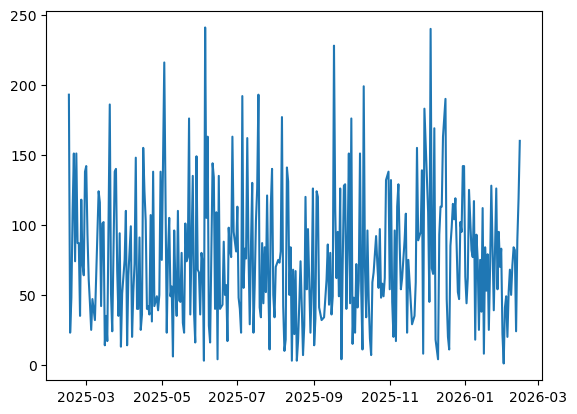

In [32]:
x = df_Quantity['Transaction_Date']
y = df_Quantity['Quantity']
plt.plot(x, y)
plt.show()

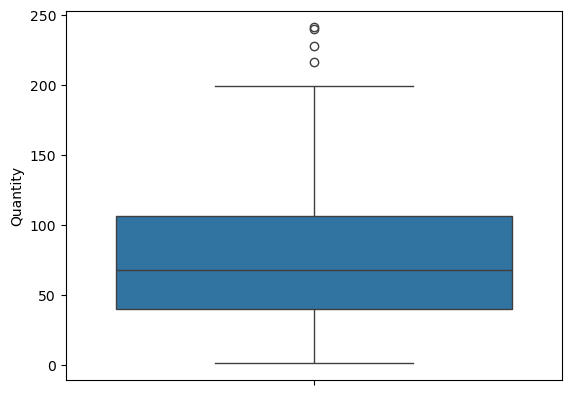

In [33]:
sns.boxplot(y='Quantity', data=df_Quantity)
plt.show()

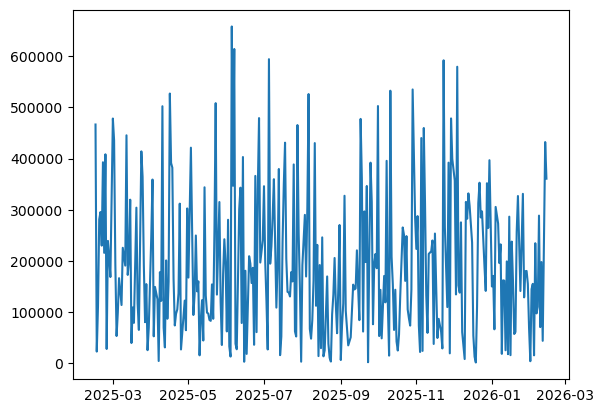

In [34]:
x = df_Sales['Transaction_Date']
y = df_Sales['Total_Amount']
plt.plot(x, y)
plt.show()

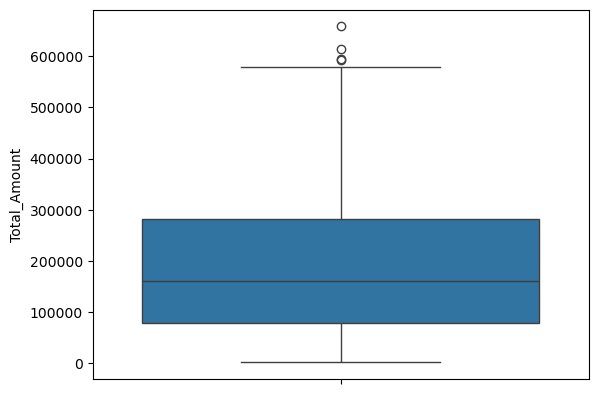

In [35]:
sns.boxplot(y='Total_Amount', data=df_Sales)
plt.show()

In [36]:
df_Quantity['rolling_7'] = df_Quantity['Quantity'].rolling(window=7, center=True).mean()

In [37]:
df_Quantity.head()

,Transaction_Date,Quantity,rolling_7
0,2025-02-15,193,NaN
1,2025-02-16,23,NaN
2,2025-02-17,48,NaN
3,2025-02-18,110,107.142857
4,2025-02-19,151,92.000000


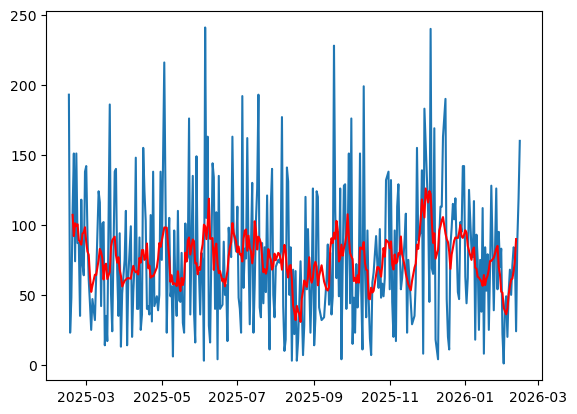

In [38]:
plt.plot(df_Quantity['Transaction_Date'],
         df_Quantity['Quantity'],
         label='Quantity')

plt.plot(df_Quantity['Transaction_Date'],
         df_Quantity['rolling_7'],
         label='Rolling Average',
         color='red')

plt.show()

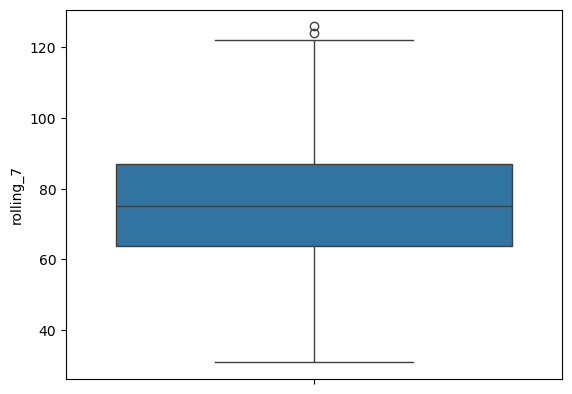

In [39]:
sns.boxplot(y='rolling_7', data=df_Quantity)
plt.show()

In [40]:
df_Quantity.tail(10)

,Transaction_Date,Quantity,rolling_7
325,2026-02-05,52,50.142857
326,2026-02-06,68,56.285714
327,2026-02-07,50,61.000000
328,2026-02-08,71,61.571429
329,2026-02-09,84,66.857143
330,2026-02-10,82,74.142857
331,2026-02-11,24,89.857143
332,2026-02-12,89,NaN
333,2026-02-13,119,NaN
334,2026-02-14,160,NaN


In [41]:
df_Quantity.head(10)

,Transaction_Date,Quantity,rolling_7
0,2025-02-15,193,NaN
1,2025-02-16,23,NaN
2,2025-02-17,48,NaN
3,2025-02-18,110,107.142857
4,2025-02-19,151,92.000000
5,2025-02-20,74,101.142857
6,2025-02-21,151,99.285714
7,2025-02-22,87,100.428571
8,2025-02-23,87,89.142857
9,2025-02-24,35,87.714286


In [42]:
from statsmodels.tsa.seasonal import STL

In [43]:
stl = STL(df_Quantity['Quantity'], period=7)
res = stl.fit()

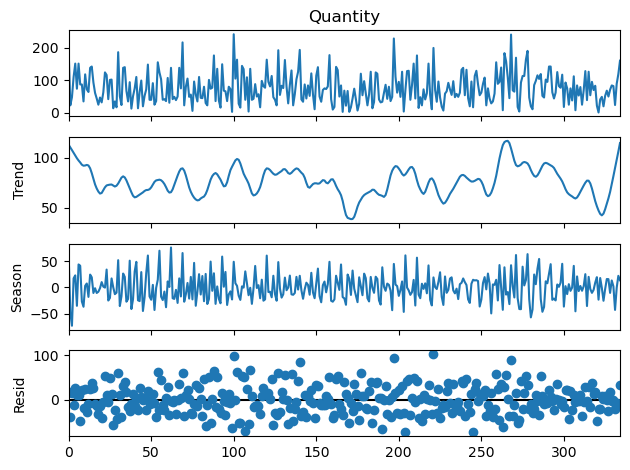

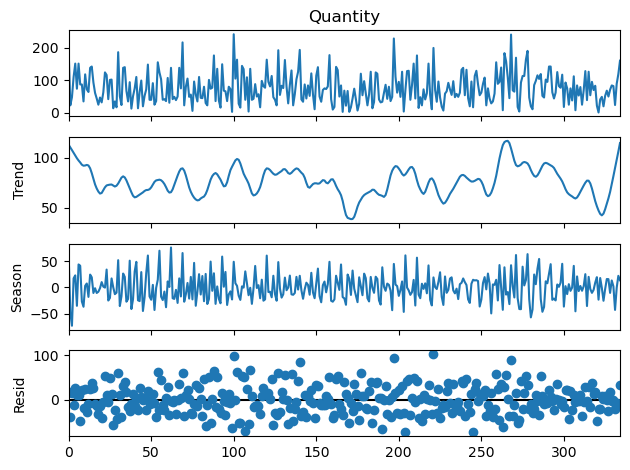

In [44]:
res.plot()

In [45]:
stl = STL(df_Quantity['Quantity'], period=30)
res = stl.fit()

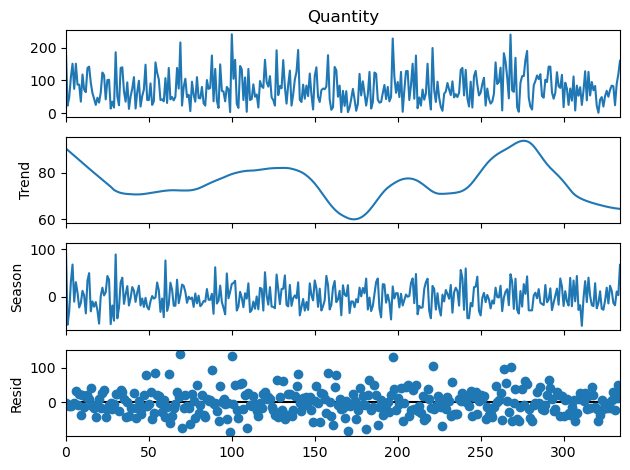

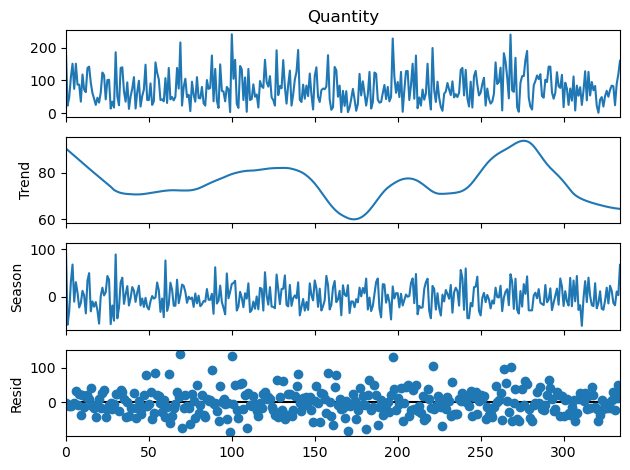

In [46]:
res.plot()

In [50]:
#pip install prophet

In [52]:
Q1 = df_Quantity['Quantity'].quantile(0.25)
Q3 = df_Quantity['Quantity'].quantile(0.75)

IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR

outliers = df_Quantity[df_Quantity['Quantity'] > upper]

In [54]:
outliers

,Transaction_Date,Quantity,rolling_7
69,2025-05-03,216,98.142857
100,2025-06-05,241,99.000000
197,2025-09-17,228,94.428571
268,2025-12-04,240,122.142857


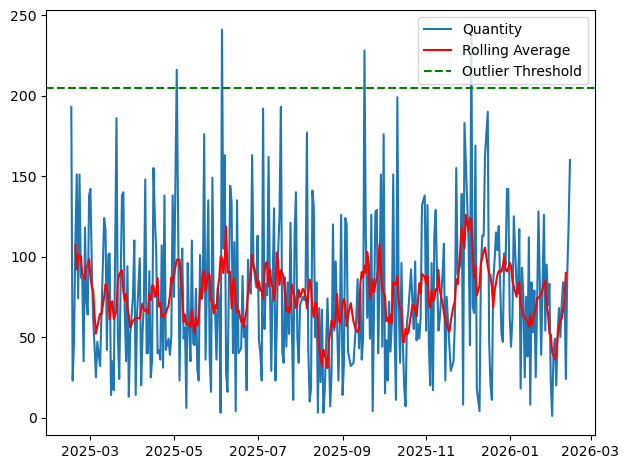

In [56]:
plt.plot(df_Quantity['Transaction_Date'],
         df_Quantity['Quantity'],
         label='Quantity')

plt.plot(df_Quantity['Transaction_Date'],
         df_Quantity['rolling_7'],
         label='Rolling Average',
         color='red')

plt.axhline(y=upper,
            label='Outlier Threshold',
            color='green',
            linestyle='--')

plt.legend()

plt.tight_layout()

plt.show()